# Deploy to ADES

Based on an AI-coded repo that uses the EODH `eoap-gen` to auto-generate a CWL file:

https://github.com/agstephens/reservoir-drought-eoap

## From the README

An EO Application Package that measures how much a lake or reservoir has shrunk
between winter and summer, built from plain Python scripts with
[`eoap-gen`](https://github.com/EO-DataHub/eoap-gen).

You give it **a point in the middle of a water body** and **a year**. It:

1. **finds scenes** – searches the EODH Sentinel-2 ARD catalogue (`sentinel2_ard`,
   CEDA) for a winter month (default January) and a summer month (default July),
   keeps only acquisitions in a 10:00–13:00 UTC window, and chooses the scene with
   the least cloud *over the lake itself* using the ARD cloud and valid-pixel masks;
2. **delineates the water** in each scene (run as a CWL scatter, one job per season) –
   MNDWI from B03/B11, an automatic Otsu threshold, a little morphological clean-up,
   and the connected water body under (or nearest to) your point. The window grows
   automatically if the lake is bigger than the initial 3 km half-width;
3. **compares** the two – an annotated longitude/latitude plot of both shorelines and
   the exposed bed (no basemap), the exposed area as GeoJSON, and a `summary.json`
   with areas, % change and a simple volume estimate;
4. **writes a STAC catalogue** linking every output, which is what the EODH ADES
   needs to put results into your workspace.

The defaults are **Wimbleball Lake, Exmoor** (51.067 N, 3.467 W), which the Environment
Agency classed as *exceptionally low* (54 % full) at the end of July 2026. EODH has a
1.9 %-cloud scene on 3 Jan 2026 and a 1.5 %-cloud scene on 9 Jul 2026 for this tile
(T30UVB, relative orbit 37), so the January → July 2026 run should be clean.

```
find_scenes ─► extract_water ×2 (winter, summer; scattered) ─► compare ─► make_stac ─► stac_output/
```

## It ran, but took forever (why?) using the ADES

This worked at the command line but took over an hour on the ADES so I aborted it.

## Here is what it does under the hood...

Here is the command-line steps in the process.

```bash
$ cd steps/find_scenes/

$ python find_scenes.py --lat 51.067 --lon -3.467 --year 2026
[winter] 9 scenes found 2025-12-18 -> 2026-02-14
  2026-01-28 11:23Z scene cloud   0.0% AOI cloud  89.9% valid 100.0%
  2026-01-23 11:22Z scene cloud   0.0% AOI cloud  93.0% valid 100.0%
  2026-01-10 11:21Z scene cloud   0.0% AOI cloud  84.6% valid 100.0%
  2026-01-03 11:23Z scene cloud   0.0% AOI cloud  81.9% valid 100.0%
  2026-02-12 11:21Z scene cloud   0.0% AOI cloud 100.0% valid 100.0%
  2026-02-07 11:22Z scene cloud   0.0% AOI cloud  99.4% valid 100.0%
[winter] chose neodc.sentinel_ard.data.sentinel_2.2026.01.03.S2B_20260103_latn510lonw0036_T30UVB_ORB037_20260103131418_utm30n_osgb (sun elevation 15.1 deg)
[summer] 14 scenes found 2026-06-17 -> 2026-08-14
  2026-07-29 11:21Z scene cloud   0.0% AOI cloud  65.2% valid 100.0%
  2026-07-27 11:21Z scene cloud   0.0% AOI cloud  99.0% valid 100.0%
  2026-07-22 11:21Z scene cloud   0.0% AOI cloud  13.9% valid 100.0%
  2026-07-19 11:21Z scene cloud   0.0% AOI cloud  58.4% valid 100.0%
  2026-07-17 11:21Z scene cloud   0.0% AOI cloud  15.5% valid 100.0%
  2026-07-12 11:21Z scene cloud   0.0% AOI cloud   0.6% valid 100.0%
[summer] chose neodc.sentinel_ard.data.sentinel_2.2026.07.12.S2B_20260712_latn510lonw0036_T30UVB_ORB037_20260712134812_utm30n_osgb (sun elevation 58.9 deg)

$ ls
find_scenes.py  requirements.txt  scenes.json  seasons.txt

$ cd ../extract_water/
$ python extract_water.py --scenes ../find_scenes/scenes.json --season winter --lat 51.067 --lon -3.467
winter: 0.071 km2, threshold 0.0179 -> water_winter.geojson
$ python extract_water.py --scenes ../find_scenes/scenes.json --season summer --lat 51.067 --lon -3.467
summer: 1.002 km2, threshold -0.15 -> water_summer.geojson

$ ls
extract_water.py  requirements.txt  water_summer.geojson  water_winter.geojson

$ cd ../compare/
$ python compare.py --boundaries ../extract_water/water_winter.geojson ../extract_water/water_summer.geojson --name test_lake --lat 51.067 --lon -3.467
{
  "name": "test_lake",
  "point": {
    "lat": 51.067,
    "lon": -3.467
  },
  "winter": {
    "datetime": "2026-01-03T11:23:59Z",
    "source_item_id": "neodc.sentinel_ard.data.sentinel_2.2026.01.03.S2B_20260103_latn510lonw0036_T30UVB_ORB037_20260103131418_utm30n_osgb",
    "area_m2": 71300.0,
    "perimeter_m": 2263.8,
    "sun_elevation_deg": 15.1
  },
  "summer": {
    "datetime": "2026-07-12T11:21:09Z",
    "source_item_id": "neodc.sentinel_ard.data.sentinel_2.2026.07.12.S2B_20260712_latn510lonw0036_T30UVB_ORB037_20260712134812_utm30n_osgb",
    "area_m2": 1002100.0,
    "perimeter_m": 13100.4,
    "sun_elevation_deg": 58.9
  },
  "area_change_m2": 930800.0,
  "area_change_percent": 1305.47,
  "exposed_area_m2": 11676.0,
  "volume_estimate": {
    "method": "uniform bank slope: dh = (dA / mean perimeter) * tan(slope); dV = dh * mean area",
    "bank_slope_deg": 10.0,
    "mean_shoreline_retreat_m": -121.2,
    "level_drop_m": -21.36,
    "level_drop_range_m": [
      -10.6,
      -32.47
    ],
    "volume_change_m3": 11466392,
    "volume_change_range_m3": [
      17424506,
      5689313
    ],
    "volume_change_megalitres": 11466.0
  }
}
$ ls
compare.py  requirements.txt  results
$ ls -1 results/
comparison.png
exposed_area.geojson
summary.json
water_summer.geojson
water_winter.geojson

$ cd ../make_stac/
$ python make_stac.py --results ../compare/results
STAC catalogue written with 3 items
$ ls -1
catalog.json
make_stac.py
requirements.txt
reservoir-water-extent
```

Output looks like:

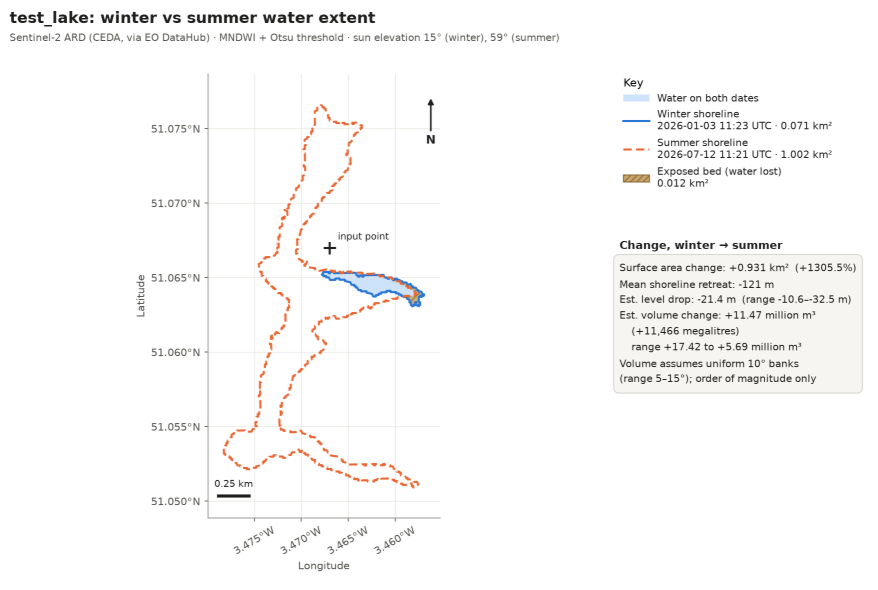

Which is here on Google Maps: https://www.google.com/maps/place/Wimbleball+Lake+Outdoor+Activity+Centre+and+Campsite/@51.0664075,-3.496045,6347m/data=!3m1!1e3!4m6!3m5!1s0x486dc3623dcfcf4b:0x5fb5528bc6b8dc18!8m2!3d51.0664078!4d-3.4780723!16s%2Fg%2F11gjm3wlhz?entry=ttu&g_ep=EgoyMDI2MTAxOS4wIKXMDSoASAFQAw%3D%3D

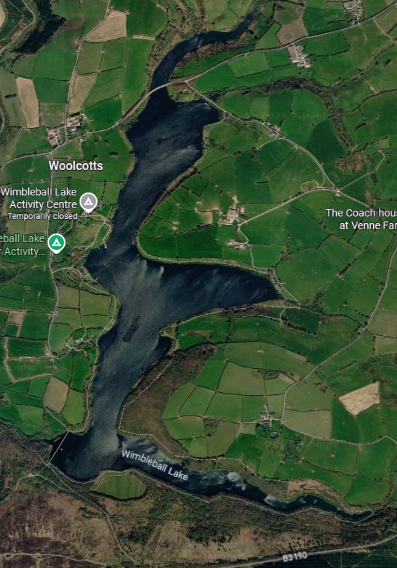

In [3]:
import os
import pyeodh
from dotenv import load_dotenv
load_dotenv()
workspace = "ag-ncas-ws1"
token = os.getenv("EODH_TOKEN")

In [37]:
clientwfr = pyeodh.Client(
    base_url="https://eodatahub.org.uk", username=workspace, token=token
)
wfr = clientwfr.get_ades()

In [38]:
# List the workflows available in the user workspace
for p in wfr.get_processes():
    print(p.id)

In [39]:
app_cwl_content = open("eoap-gen-out/cli/workflow-packed.cwl").read()

In [40]:
app_cwl_content[:200]

'$graph:\n- id: compare\n  class: CommandLineTool\n  inputs:\n  - id: boundaries\n    doc: The winter and summer water_*.geojson files\n    inputBinding:\n      prefix: --boundaries\n    type:\n      type: arra'

In [41]:
wfr.deploy_process(cwl_yaml=app_cwl_content)

In [42]:
# This one works just using a pre-canned process.
# convert_url_proc = ades.deploy_process(
#     cwl_url="https://raw.githubusercontent.com/EO-DataHub/eodhp-ades-demonstration/e4ed00b16add58f9b516921ca9ca9e1068dd27c1/convert-url-app.cwl"
# )

In [44]:
# List the workflows available in the user workspace
for p in wfr.get_processes():
    print(p.id)

echo
land-cover-change
raster-calculate-ndvi
reservoir-drought


# Now run a job

In [45]:
job = wfr.get_process("reservoir-drought").execute(
    {"lat": 51.067, "lon": -3.467, "year": 2026}
)

In [46]:
job.status

'running'

In [55]:
job.refresh()

In [56]:
job.status

'running'

## Danger - still running after 1 hour!!!

This is strange, because the command-line version runs in about 1 minute, through all steps.

In [58]:
help(job)

Help on Job in module pyeodh.ades object:

class Job(pyeodh.eodh_object.EodhObject)
 |  Job(client: 'Client', headers: 'Headers', data: 'dict', **kwargs: 'Any') -> 'None'
 |
 |  Represents ADES Job record.
 |
 |  Args:
 |      client (Client): Instance of pyeodh request client
 |      headers (Headers): Response headers received when requesting this record
 |      data (Any): Raw response data received when requesting this record
 |
 |  Method resolution order:
 |      Job
 |      pyeodh.eodh_object.EodhObject
 |      builtins.object
 |
 |  Methods defined here:
 |
 |  __init__(
 |      self,
 |      client: 'Client',
 |      headers: 'Headers',
 |      data: 'dict',
 |      **kwargs: 'Any'
 |  ) -> 'None'
 |      Initialize self.  See help(type(self)) for accurate signature.
 |
 |  delete(self) -> 'None'
 |      Stop and delete this job.
 |
 |  get_result_items(self) -> 'list[Item]'
 |      Get job outputs
 |
 |      Returns:
 |          list[Item]: List of items generated by job
 |
 

In [59]:
job.delete()

In [60]:
job.refresh()
print(job.status)

HTTPError: 500 Server Error: Internal Server Error for url: https://eodatahub.org.uk/api/catalogue/stac/catalogs/user/catalogs/ag-ncas-ws1/jobs/052d01f2-cd73-11f1-b79b-5aa5a146b801

## Test another one (that should be quick and work)

And it did work quickly!

In [61]:
# Deploy a workflow using a URL to a .cwl file hosted online
convert_url_proc = wfr.deploy_process(
    cwl_url="https://raw.githubusercontent.com/EO-DataHub/eodhp-ades-demonstration/e4ed00b16add58f9b516921ca9ca9e1068dd27c1/convert-url-app.cwl"
)
print(convert_url_proc.id, convert_url_proc.description, ": Deployed")
print("")
# List the available workflows
for p in wfr.get_processes():
    print(p.id)

convert-url Convert URL : Deployed

echo
land-cover-change
raster-calculate-ndvi
reservoir-drought
convert-url


In [62]:
# Just use the defaults
job = wfr.get_process("convert-url").execute(
    {"fn": "resize", "url": "https://eoepca.org/media_portal/images/logo6_med.original.png", "size": "50%"}
)

In [69]:
job.refresh()
job.status

'successful'

In [71]:
results = job.get_result_items()


This works:

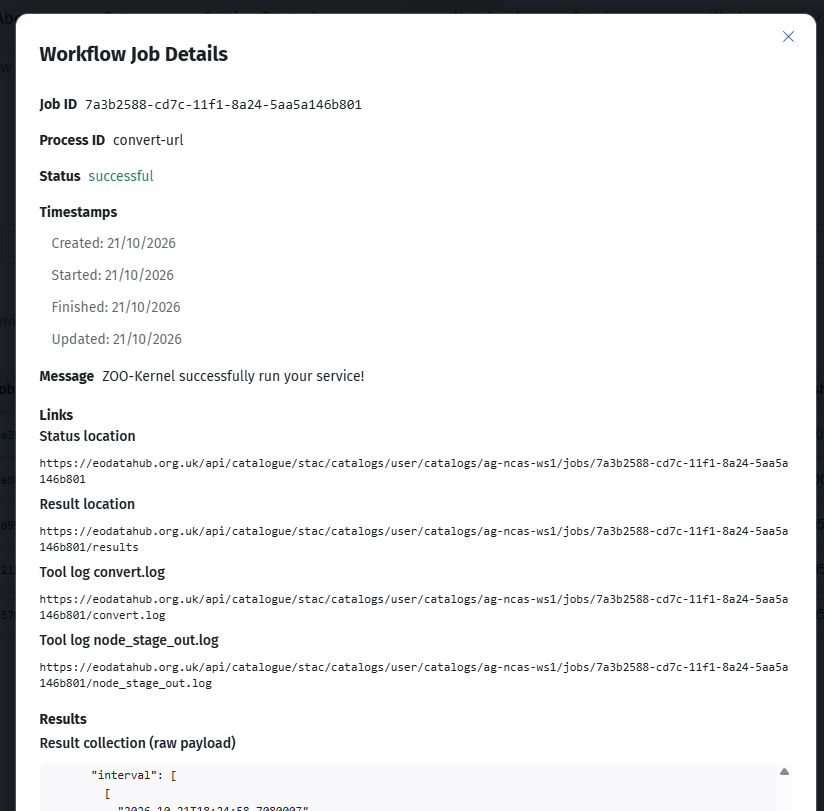

In [73]:
type(results)

list

In [74]:
len(results)

1

In [87]:
png_url = list(results[0].assets.values())[0].href

In [88]:
png_url

'https://ag-ncas-ws1.eodatahub-workspaces.org.uk/files/workspaces-eodhp/processing-results/convert-url/catalog/col_7a3b2588-cd7c-11f1-8a24-5aa5a146b801/logo6_med.original-resize.png'

In [95]:
headers = {"Authorization": f"Bearer {token}"}

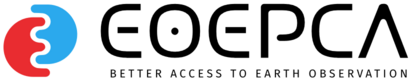

In [97]:
from IPython.display import Image
import requests

resp = requests.get(png_url, headers=headers)
resp.raise_for_status()

ctype = resp.headers.get("Content-Type", "")
# if "image" not in ctype:
#     raise RuntimeError(f"Not an image ({ctype}): {resp.text[:200]}")

with open("local.png", "wb") as f:
    f.write(resp.content)

Image(filename="local.png")